# GPT-2-style SLM on TinyStories: baseline vs. fixed training

Controlled experiment, same session, same GPU, same seed, same token budget:

* **baseline**: the original notebook's training setup (lr 1e-4 with `min_lr` 5e-4, so the cosine schedule *rises*;
  scheduler stepped every micro-batch; grad-accum 32, so few real optimizer updates).
* **fixed**: lr 6e-4 decaying to 6e-5, scheduler stepped per optimizer update, grad-accum 4 (~8x more updates).

Both use the same ~30M-param model, data, seed and number of training tokens. Shared hygiene fixes in both
(they're bugs, not the thing being tested): unscale grads before clipping, dtype by GPU capability, `model.eval()` for generation.

Evaluation: loss and perplexity on the **full** validation split (deterministic, non-overlapping windows),
a unigram-frequency baseline for context, and fixed-seed samples from the same prompts.

In [4]:
!pip -q install tiktoken datasets
from google.colab import drive
drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/slm_eval'   # results survive a Colab disconnect
import os; os.makedirs(OUT, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
# ---- knobs ----
SMOKE = False                 # True = tiny 2-minute end-to-end check before the real run
TOKENS_PER_RUN = 40_000_000   # original notebook used ~82M (20k iters x 32 x 128); 40M keeps both runs to a free-tier T4 session
TRAIN_STORIES = 500_000       # ~95M tokens of TinyStories train, more than one run consumes
BLOCK, MICRO_BS = 128, 32
if SMOKE: TOKENS_PER_RUN, TRAIN_STORIES = 400_000, 20_000; OUT += '/smoke'; os.makedirs(OUT, exist_ok=True)

In [6]:
import numpy as np, tiktoken
from datasets import load_dataset
enc = tiktoken.get_encoding('gpt2')

def to_bin(split, n, path):
    if os.path.exists(path): return
    ds = load_dataset('roneneldan/TinyStories', split=split)
    if n: ds = ds.select(range(min(n, len(ds))))
    ds = ds.map(lambda b: {'ids': enc.encode_ordinary_batch(b['text'])}, batched=True, remove_columns=['text'], num_proc=2)
    np.concatenate([np.array(x, dtype=np.uint16) for x in ds['ids']]).tofile(path)  # max token id 50256 < 2**16

to_bin('train', TRAIN_STORIES, '/content/train.bin')
to_bin('validation', 2_000 if SMOKE else None, '/content/val.bin')
train_data = np.memmap('/content/train.bin', dtype=np.uint16, mode='r')
val_data = np.memmap('/content/val.bin', dtype=np.uint16, mode='r')
print(f'train tokens {len(train_data):,}  val tokens {len(val_data):,}')

train tokens 111,798,425  val tokens 4,743,928


In [7]:
import math, torch, torch.nn as nn, torch.nn.functional as F
from dataclasses import dataclass

@dataclass
class GPTConfig:
    block_size: int = 128; vocab_size: int = 50257; n_layer: int = 6; n_head: int = 6; n_embd: int = 384
    dropout: float = 0.1; bias: bool = True

class CausalSelfAttention(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.c_attn = nn.Linear(c.n_embd, 3 * c.n_embd, bias=c.bias)
        self.c_proj = nn.Linear(c.n_embd, c.n_embd, bias=c.bias)
        self.drop = nn.Dropout(c.dropout); self.p = c.dropout; self.n_head = c.n_head
    def forward(self, x):
        B, T, C = x.shape
        q, k, v = (t.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) for t in self.c_attn(x).split(C, dim=2))
        y = F.scaled_dot_product_attention(q, k, v, dropout_p=self.p if self.training else 0.0, is_causal=True)
        return self.drop(self.c_proj(y.transpose(1, 2).contiguous().view(B, T, C)))

class Block(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.ln1, self.ln2 = nn.LayerNorm(c.n_embd, bias=c.bias), nn.LayerNorm(c.n_embd, bias=c.bias)
        self.attn = CausalSelfAttention(c)
        self.mlp = nn.Sequential(nn.Linear(c.n_embd, 4 * c.n_embd, bias=c.bias), nn.GELU(),
                                 nn.Linear(4 * c.n_embd, c.n_embd, bias=c.bias), nn.Dropout(c.dropout))
    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        return x + self.mlp(self.ln2(x))

class GPT(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.c = c
        self.wte, self.wpe = nn.Embedding(c.vocab_size, c.n_embd), nn.Embedding(c.block_size, c.n_embd)
        self.drop = nn.Dropout(c.dropout)
        self.h = nn.ModuleList(Block(c) for _ in range(c.n_layer))
        self.ln_f = nn.LayerNorm(c.n_embd, bias=c.bias)
        self.lm_head = nn.Linear(c.n_embd, c.vocab_size, bias=False)
        self.wte.weight = self.lm_head.weight  # weight tying
        for m in self.modules():
            if isinstance(m, (nn.Linear, nn.Embedding)): nn.init.normal_(m.weight, 0.0, 0.02)
            if isinstance(m, nn.Linear) and m.bias is not None: nn.init.zeros_(m.bias)
        for n, p in self.named_parameters():   # GPT-2 scaled init on residual projections
            if n.endswith('c_proj.weight') or n.endswith('mlp.2.weight'): nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * c.n_layer))
    def forward(self, idx, targets=None):
        x = self.drop(self.wte(idx) + self.wpe(torch.arange(idx.size(1), device=idx.device)))
        for b in self.h: x = b(x)
        logits = self.lm_head(self.ln_f(x))
        return logits, (None if targets is None else F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1)))
    @torch.no_grad()
    def generate(self, idx, n, temperature=0.8, top_k=50):
        for _ in range(n):
            logits = self(idx[:, -self.c.block_size:])[0][:, -1, :] / temperature
            v, _ = torch.topk(logits, top_k); logits[logits < v[:, [-1]]] = -float('inf')
            idx = torch.cat((idx, torch.multinomial(F.softmax(logits, -1), 1)), 1)
        return idx

device = 'cuda'
assert torch.cuda.is_available(), 'Runtime > Change runtime type > GPU'
# T4 is sm75: no native bf16 (is_bf16_supported() can say True via slow emulation), so decide by capability
dtype = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
print(torch.cuda.get_device_name(), dtype, f'{sum(p.numel() for p in GPT(GPTConfig()).parameters())/1e6:.1f}M params')

Tesla T4 torch.float16 30.0M params


In [8]:
def get_batch(data, bs=MICRO_BS):
    ix = np.random.randint(0, len(data) - BLOCK - 1, bs)
    x = torch.from_numpy(np.stack([data[i:i+BLOCK] for i in ix]).astype(np.int64))
    y = torch.from_numpy(np.stack([data[i+1:i+1+BLOCK] for i in ix]).astype(np.int64))
    return x.pin_memory().to(device, non_blocking=True), y.pin_memory().to(device, non_blocking=True)

@torch.no_grad()
def full_val_loss(model, bs=64):
    # deterministic: every non-overlapping 128-token window of the whole validation split
    model.eval()
    n = (len(val_data) - 1) // BLOCK
    tot, cnt = 0.0, 0
    for s in range(0, n, bs):
        idx = np.arange(s, min(s + bs, n)) * BLOCK
        x = torch.from_numpy(np.stack([val_data[i:i+BLOCK] for i in idx]).astype(np.int64)).to(device)
        y = torch.from_numpy(np.stack([val_data[i+1:i+1+BLOCK] for i in idx]).astype(np.int64)).to(device)
        with torch.autocast('cuda', dtype=dtype):
            logits, _ = model(x)
        tot += F.cross_entropy(logits.float().view(-1, logits.size(-1)), y.view(-1), reduction='sum').item(); cnt += y.numel()
    model.train()
    return tot / cnt

@torch.no_grad()
def quick_loss(model, data, iters=50):
    model.eval(); out = []
    for _ in range(iters):
        x, y = get_batch(data)
        with torch.autocast('cuda', dtype=dtype): out.append(model(x, y)[1].item())
    model.train(); return float(np.mean(out))

# Context baseline: a model that ignores context and just predicts token frequency (add-one smoothed)
counts = np.bincount(train_data, minlength=50257).astype(np.float64) + 1
uni_loss = float(-np.log(counts / counts.sum())[val_data].mean())
print(f'unigram baseline: val loss {uni_loss:.3f}  ppl {math.exp(uni_loss):.0f}')

unigram baseline: val loss 5.965  ppl 390


In [9]:
from torch.optim.lr_scheduler import LinearLR, SequentialLR, CosineAnnealingLR

RUNS = {
    # the original notebook's choices, verbatim: schedule stepped per micro-batch, min_lr > lr
    'baseline': dict(lr=1e-4, min_lr=5e-4, accum=32, warmup_frac=0.05, sched_per_micro=True),
    'fixed':    dict(lr=6e-4, min_lr=6e-5, accum=4,  warmup_frac=0.05, sched_per_micro=False),
}

def train(name, lr, min_lr, accum, warmup_frac, sched_per_micro, n_evals=20):
    torch.manual_seed(42); np.random.seed(42)
    model = GPT(GPTConfig()).to(device)
    micro_steps = TOKENS_PER_RUN // (MICRO_BS * BLOCK)
    opt_steps = micro_steps // accum
    sched_len = micro_steps if sched_per_micro else opt_steps
    warm = max(1, int(warmup_frac * sched_len))
    opt = torch.optim.AdamW(model.parameters(), lr=lr, betas=(0.9, 0.95), weight_decay=0.1)
    sched = SequentialLR(opt, [LinearLR(opt, start_factor=0.01, total_iters=warm),
                               CosineAnnealingLR(opt, T_max=sched_len - warm, eta_min=min_lr)], milestones=[warm])
    scaler = torch.amp.GradScaler('cuda', enabled=(dtype == torch.float16))
    curve, every = [], max(1, micro_steps // n_evals)
    for step in tqdm(range(micro_steps), desc=name):
        x, y = get_batch(train_data)
        with torch.autocast('cuda', dtype=dtype):
            loss = model(x, y)[1] / accum
        scaler.scale(loss).backward()
        if (step + 1) % accum == 0:
            scaler.unscale_(opt)                      # clip real grads, not fp16-scaled ones
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
            if not sched_per_micro: sched.step()
        if sched_per_micro: sched.step()
        if (step + 1) % every == 0:
            curve.append(dict(tokens=(step + 1) * MICRO_BS * BLOCK, lr=opt.param_groups[0]['lr'],
                              train=quick_loss(model, train_data), val=quick_loss(model, val_data)))
            print(curve[-1])
    torch.save(model.state_dict(), f'{OUT}/{name}.pt')
    return model, dict(name=name, opt_steps=opt_steps, tokens=TOKENS_PER_RUN, curve=curve)

from tqdm.auto import tqdm
import json
results = {}
for name, cfg in RUNS.items():
    path = f'{OUT}/{name}.json'
    if os.path.exists(path) and not SMOKE:   # resume at run granularity after a disconnect
        results[name] = json.load(open(path)); print('loaded', name); continue
    model, r = train(name, **cfg)
    r['val_loss'] = full_val_loss(model); r['val_ppl'] = math.exp(r['val_loss'])
    results[name] = r
    json.dump(r, open(path, 'w'), indent=1)
    print(f"{name}: {r['opt_steps']} optimizer updates, full-val loss {r['val_loss']:.3f}, ppl {r['val_ppl']:.2f}")

loaded baseline
loaded fixed


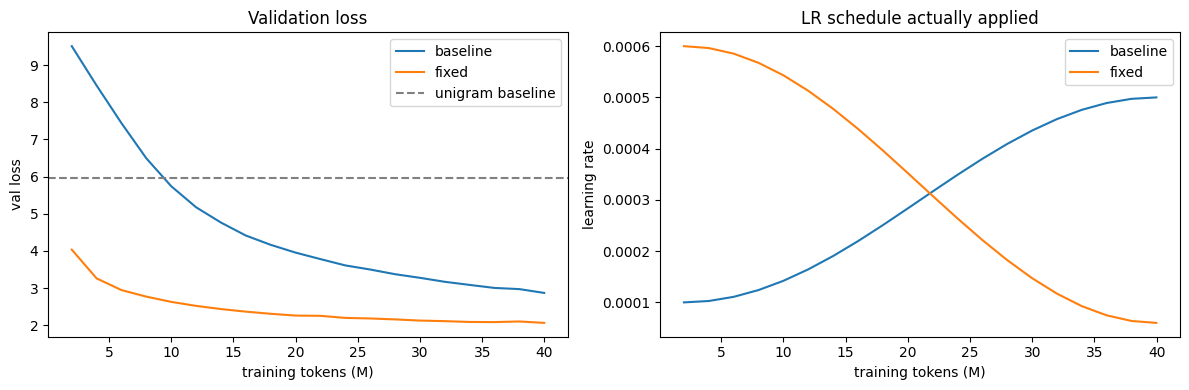

run         updates  val loss      ppl
unigram           -     5.965    389.6
baseline        305     2.882    17.84
fixed          2441     2.077     7.98


In [10]:
import matplotlib.pyplot as plt
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
for name, r in results.items():
    t = [c['tokens'] / 1e6 for c in r['curve']]
    a.plot(t, [c['val'] for c in r['curve']], label=name); b.plot(t, [c['lr'] for c in r['curve']], label=name)
a.axhline(uni_loss, ls='--', c='gray', label='unigram baseline')
a.set(xlabel='training tokens (M)', ylabel='val loss', title='Validation loss'); a.legend()
b.set(xlabel='training tokens (M)', ylabel='learning rate', title='LR schedule actually applied'); b.legend()
plt.tight_layout(); plt.savefig(f'{OUT}/curves.png', dpi=150); plt.show()

print(f"{'run':10} {'updates':>8} {'val loss':>9} {'ppl':>8}")
print(f"{'unigram':10} {'-':>8} {uni_loss:9.3f} {math.exp(uni_loss):8.1f}")
for name, r in results.items():
    print(f"{name:10} {r['opt_steps']:8d} {r['val_loss']:9.3f} {r['val_ppl']:8.2f}")

In [11]:
prompts = ['Once upon a time there was a pumpkin.', 'A little girl went to the woods', 'Tom was sad because']
samples = {}
for name in results:
    m = GPT(GPTConfig()).to(device); m.load_state_dict(torch.load(f'{OUT}/{name}.pt')); m.eval()
    samples[name] = []
    for p in prompts:
        torch.manual_seed(0)
        out = enc.decode(m.generate(torch.tensor([enc.encode_ordinary(p)], device=device), 120)[0].tolist())
        samples[name].append(out); print(f'--- {name} | {p}\n{out}\n')
json.dump(samples, open(f'{OUT}/samples.json', 'w'), indent=1)
print('saved to', OUT)

--- baseline | Once upon a time there was a pumpkin.
Once upon a time there was a pumpkin. The bunny was very sad and wished the squirrel would play with his friends. One day, he spotted something special and found a little girl that was shining. She couldn't find it, he was very excited.

She tried to keep it up, but the little one was too big and it could not fly away. Suddenly, something bad happened. The little girl got sad and asked her mum for help. The little girl thought about the little girl was okay. 

"I'm sorry!" said the girl.

The bear kept his head and waited. She opened the door

--- baseline | A little girl went to the woods
A little girl went to the woods. She saw a big, red dog, and a bug. The little girl was scared, but she felt mean. She wanted to buy another ball. She tried to catch it, but it was too fast.

"I'm sorry, Lily. I couldn't wait to get it from it. The dog said, "Ben, I was hurt a mouse. I don't want to play anymore."

Tom and Lily ran to the man and r